<a href="https://colab.research.google.com/github/caryanefr-code/Miniprojeto_Caryane_T8/blob/main/Miniprojeto_Caryane_T8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# MINI-PROJETO AVALIATIVO: ANÁLISE EXPLORATÓRIA E TRATAMENTO DE DADOS VAREJO
 Módulo: Análise de Dados com Python (SCTEC - T8 )

 Unidade de Análise: Registro de Item Adquirido por Cliente em uma Compra (Nota Fiscal)

Autora: Caryane Ferreira Ribeiro



In [3]:
# IMPORTAÇÃO DE BIBLIOTECAS E CONFIGURAÇÃO ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configurações visuais e de exibição
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
sns.set_theme(style="whitegrid")
warnings.filterwarnings('ignore')

print("✓ Bibliotecas carregadas com sucesso!")

✓ Bibliotecas carregadas com sucesso!


In [5]:
# ---LEITURA E DIAGNÓSTICO INICIAL (SPRINT 1) ---
# Carregamento do arquivo com separador correto (;)
caminho_arquivo = "Base Varejo.csv"  # Certifique-se de fazer o upload no Colab
df_raw = pd.read_csv(caminho_arquivo, sep=';')

print("=" * 70)
print("DIAGNÓSTICO INICIAL DE QUALIDADE DA BASE (DADOS BRUTOS)")
print("=" * 70)

# 1. Dimensões originais
linhas_brutas, colunas_brutas = df_raw.shape
print(f"• Dimensão total da base bruta: {linhas_brutas:,} linhas x {colunas_brutas} colunas")

# 2. Identificação de colunas vazias resultantes do delimitador
colunas_vazias = [c for c in df_raw.columns if 'Unnamed' in c]
print(f"• Colunas residuais/inúteis detectadas: {colunas_vazias}")

# 3. Remoção imediata de colunas residuais sem alteração nos dados válidos
df = df_raw.drop(columns=colunas_vazias).copy()

# 4. Verificação de Nulos e Textos Vazios
nulos_por_coluna = df.isna().sum()
textos_vazios = {}
for col in df.select_dtypes(include=['object']).columns:
    vazios = df[col].astype(str).str.strip().eq("").sum()
    textos_vazios[col] = vazios

print("\n• Mapeamento de Valores Ausentes (np.nan):")
print(nulos_por_coluna)

print("\n• Mapeamento de Textos Vazios (Strings de Espaço em Branco):")
for k, v in textos_vazios.items():
    print(f"  - {k}: {v} registros vazios")

# 5. Verificação de Duplicatas Exatas
duplicatas_exatas = df.duplicated().sum()
perc_duplicatas = (duplicatas_exatas / linhas_brutas) * 100
print(f"\n• Duplicatas Exatas Encontradas: {duplicatas_exatas:,} registros ({perc_duplicatas:.2f}% do total)")

# 6. Unidade de Análise e Identificadores Únicos
compras_unicas = df['CO_ID'].nunique()
clientes_unicos = df['CL_ID'].nunique()
produtos_unicos = df['PR_ID'].nunique()

print(f"\n• Entidades Únicas Identificadas:")
print(f"  - Transações/Notas Fiscais (CO_ID): {compras_unicas:,}")
print(f"  - Clientes (CL_ID): {clientes_unicos:,}")
print(f"  - Produtos SKUs (PR_ID): {produtos_unicos:,}")

DIAGNÓSTICO INICIAL DE QUALIDADE DA BASE (DADOS BRUTOS)
• Dimensão total da base bruta: 830,000 linhas x 14 colunas
• Colunas residuais/inúteis detectadas: ['Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13']

• Mapeamento de Valores Ausentes (np.nan):
DATA         0
CO_ID        0
CL_ID        0
CL_GENERO    0
CL_EC        0
CL_FHL       0
CL_SEG       0
PR_ID        0
PR_CAT       0
PR_NOME      0
dtype: int64

• Mapeamento de Textos Vazios (Strings de Espaço em Branco):
  - DATA: 0 registros vazios
  - CL_GENERO: 0 registros vazios
  - CL_SEG: 0 registros vazios
  - PR_CAT: 0 registros vazios
  - PR_NOME: 0 registros vazios

• Duplicatas Exatas Encontradas: 96,553 registros (11.63% do total)

• Entidades Únicas Identificadas:
  - Transações/Notas Fiscais (CO_ID): 18,471
  - Clientes (CL_ID): 1,000
  - Produtos SKUs (PR_ID): 229


In [6]:
# --- IMPLEMENTAÇÃO DE FUNÇÕES REUTILIZÁVEIS ---
# A avaliação exige no mínimo duas funções com parâmetro e RETORNO (return)

def padronizar_texto(valor):
    """
    Função 1: Higieniza e padroniza strings removendo espaços nas extremidades,
    espaços duplicados internos e ajustando a caixa do texto.
    """
    if pd.isna(valor) or valor is None:
        return np.nan
    texto = str(valor).strip()
    if texto == "" or texto.upper() in ["#N/D", "NAN", "NULL", "NONE"]:
        return "NÃO INFORMADO"
    return " ".join(texto.upper().split())

def resumo_numerico(serie):
    """
    Função 2: Recebe uma Series numéricas e retorna um dicionário estruturado
    com estatísticas descritivas completas.
    """
    if not isinstance(serie, pd.Series):
        raise TypeError("O argumento deve ser um pandas Series.")

    dados_validos = serie.dropna()
    return {
        "contagem": int(dados_validos.count()),
        "media": float(dados_validos.mean()),
        "mediana": float(dados_validos.median()),
        "minimo": float(dados_validos.min()),
        "maximo": float(dados_validos.max()),
        "desvio_padrao": float(dados_validos.std())
    }

print("\n✓ Funções reutilizáveis `padronizar_texto` e `resumo_numerico` declaradas com sucesso!")


✓ Funções reutilizáveis `padronizar_texto` e `resumo_numerico` declaradas com sucesso!


In [7]:
# ---  TRATAMENTO E LIMPEZA JUSTIFICADA (SPRINTS 2 E 3) ---
print("\n" + "=" * 70)
print("EXECUTANDO ETAPA DE LIMPEZA E PADRONIZAÇÃO DE DADOS")
print("=" * 70)

# 1. Remoção Justificada de Duplicatas Exatas
# Justificativa: Registros 100% idênticos em todas as colunas representam duplicação de inserção no BD.
df_limpo = df.drop_duplicates().copy()
print(f"1. Remoção de Duplicatas Exatas: {duplicatas_exatas:,} linhas removidas. Restantes: {len(df_limpo):,} linhas.")

# 2. Padronização de Colunas Textuais utilizando a Função Criada
colunas_texto = ['PR_CAT', 'PR_NOME', 'CL_GENERO', 'CL_SEG']
for col in colunas_texto:
    df_limpo[col] = df_limpo[col].apply(padronizar_texto)

print("2. Colunas de texto sanitizadas e padronizadas em caixa alta sem espaços sobressalentes.")

# 3. Conversão de Tipos (DATA -> datetime)
df_limpo['DATA_DT'] = pd.to_datetime(df_limpo['DATA'], format='%d/%m/%Y', errors='coerce')
periodo_min = df_limpo['DATA_DT'].min().strftime('%d/%m/%Y')
periodo_max = df_limpo['DATA_DT'].max().strftime('%d/%m/%Y')
print(f"3. Campo DATA convertido para datetime. Período analisado: {periodo_min} até {periodo_max}.")

# 4. Mapeamento de Códigos Categóricos para Melhor Entendimento (CL_EC - Estado Civil)
mapeamento_ec = {
    1: "Casado/União Estável",
    2: "Divorciado",
    3: "Separado",
    4: "Solteiro",
    5: "Viúvo"
}
df_limpo['CL_EC_DESC'] = df_limpo['CL_EC'].map(mapeamento_ec)
print("4. Estado civil (CL_EC) mapeado com descrições legíveis para negócio.")


EXECUTANDO ETAPA DE LIMPEZA E PADRONIZAÇÃO DE DADOS
1. Remoção de Duplicatas Exatas: 96,553 linhas removidas. Restantes: 733,447 linhas.
2. Colunas de texto sanitizadas e padronizadas em caixa alta sem espaços sobressalentes.
3. Campo DATA convertido para datetime. Período analisado: 04/01/2019 até 08/12/2022.
4. Estado civil (CL_EC) mapeado com descrições legíveis para negócio.


In [8]:
# ---  ANÁLISE EXPLORATÓRIA, FILTROS E AGRUPAMENTOS (SPRINTS 4 A 6) ---
print("\n" + "=" * 70)
print("ANÁLISE EXPLORATÓRIA E OPERAÇÕES DE AGRUPAMENTO (GROUPBY)")
print("=" * 70)

# Aplicando Função 2 para analisar a distribuição de itens por compra
itens_por_compra = df_limpo.groupby('CO_ID').size()
estatisticas_compra = resumo_numerico(itens_por_compra)

print("\n--- Estatísticas de Itens por Compra (Nota Fiscal) ---")
for k, v in estatisticas_compra.items():
    print(f"  • {k.capitalize()}: {v:.2f}")

# FILTRO DE NEGÓCIO COM SIGNIFICADO:
# Identificar compras de grande volume (compras com mais de 50 itens - "compras do mês/abastecimento")
compras_grande_volume = itens_por_compra[itens_por_compra > 50]
total_compras_vol = len(compras_grande_volume)
perc_compras_vol = (total_compras_vol / df_limpo['CO_ID'].nunique()) * 100
print(f"\n• Filtro de Negócio (Compras de Grande Volume > 50 itens):")
print(f"  Representam {total_compras_vol:,} notas fiscais ({perc_compras_vol:.2f}% do total de compras únicas).")

# AGRUPAMENTO 1: Volume de Itens Adquiridos por Categoria de Produto
groupby_categoria = df_limpo.groupby('PR_CAT').agg(
    total_itens=('PR_ID', 'count'),
    produtos_distintos=('PR_ID', 'nunique')
).reset_index().sort_values(by='total_itens', ascending=False)

groupby_categoria['participacao_pct'] = (groupby_categoria['total_itens'] / len(df_limpo)) * 100

print("\n--- AGRUPAMENTO 1: Participação por Categoria de Produto ---")
print(groupby_categoria.to_string(index=False))

# AGRUPAMENTO 2: Perfil Consumidor por Classe Econômica e Estado Civil (Volume + Ticket em Itens)
groupby_perfil = df_limpo.groupby(['CL_SEG', 'CL_EC_DESC']).agg(
    total_registros=('PR_ID', 'count'),
    clientes_unicos=('CL_ID', 'nunique'),
    compras_unicas=('CO_ID', 'nunique')
).reset_index()

groupby_perfil['media_itens_por_compra'] = groupby_perfil['total_registros'] / groupby_perfil['compras_unicas']
print("\n--- AGRUPAMENTO 2: Perfil do Consumidor (Segmento x Estado Civil) ---")
print(groupby_perfil.head(10).to_string(index=False))


ANÁLISE EXPLORATÓRIA E OPERAÇÕES DE AGRUPAMENTO (GROUPBY)

--- Estatísticas de Itens por Compra (Nota Fiscal) ---
  • Contagem: 18471.00
  • Media: 39.71
  • Mediana: 41.00
  • Minimo: 1.00
  • Maximo: 81.00
  • Desvio_padrao: 21.34

• Filtro de Negócio (Compras de Grande Volume > 50 itens):
  Representam 6,742 notas fiscais (36.50% do total de compras únicas).

--- AGRUPAMENTO 1: Participação por Categoria de Produto ---
       PR_CAT  total_itens  produtos_distintos  participacao_pct
    ALIMENTOS       384197                 120             52.38
      HIGIENE       137702                  43             18.77
      LIMPEZA       128632                  40             17.54
      BEBIDAS        38264                  12              5.22
          PET        28553                   9              3.89
   ACESSORIOS        12871                   4              1.75
NÃO INFORMADO         3228                   1              0.44

--- AGRUPAMENTO 2: Perfil do Consumidor (Segmento x 


GERANDO GRÁFICOS EXPLORATÓRIOS (HISTOGRAMA, BOXPLOT E BARRAS)


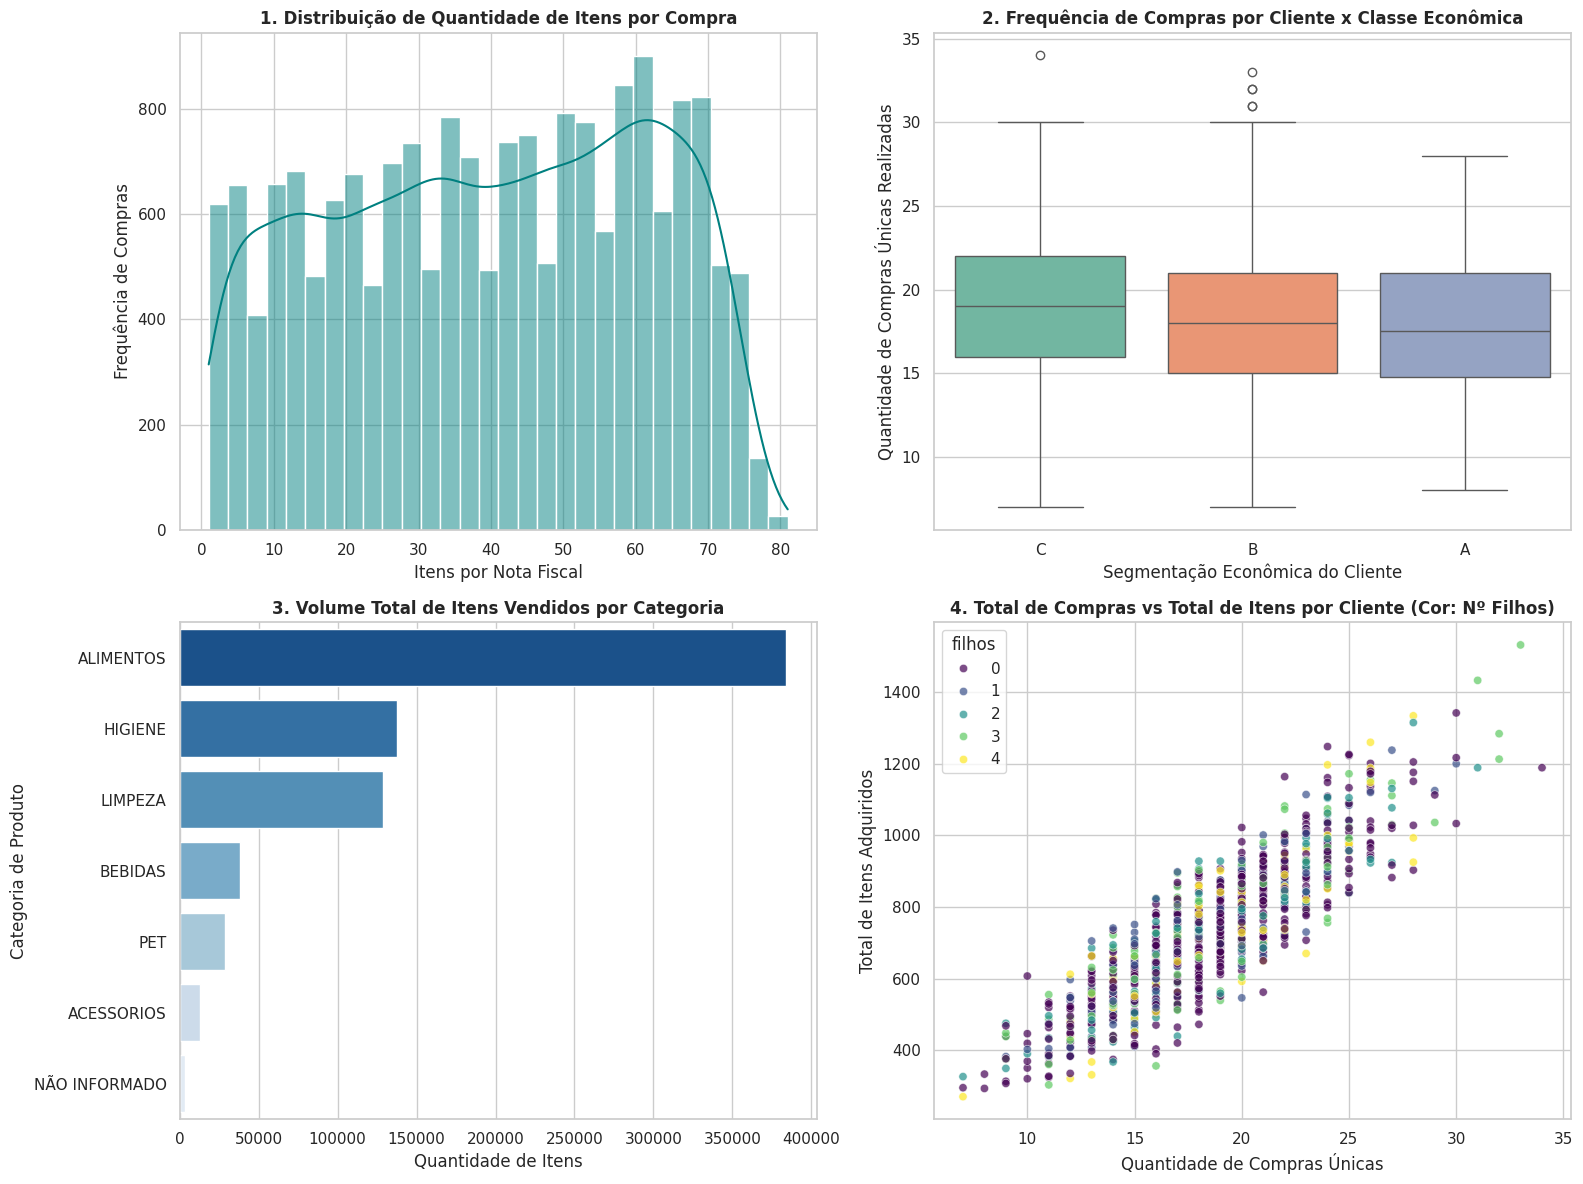

In [9]:
# ---  GERAÇÃO DE VISUALIZAÇÕES GRÁFICAS ---
print("\n" + "=" * 70)
print("GERANDO GRÁFICOS EXPLORATÓRIOS (HISTOGRAMA, BOXPLOT E BARRAS)")
print("=" * 70)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Gráfico 1: Histograma de Itens por Compra
sns.histplot(itens_por_compra, bins=30, kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title("1. Distribuição de Quantidade de Itens por Compra", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Itens por Nota Fiscal")
axes[0, 0].set_ylabel("Frequência de Compras")

# Gráfico 2: Boxplot de Compras por Cliente divididos por Segmento Econômico
compras_por_cliente_seg = df_limpo.groupby(['CL_ID', 'CL_SEG'])['CO_ID'].nunique().reset_index()
sns.boxplot(data=compras_por_cliente_seg, x='CL_SEG', y='CO_ID', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title("2. Frequência de Compras por Cliente x Classe Econômica", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Segmentação Econômica do Cliente")
axes[0, 1].set_ylabel("Quantidade de Compras Únicas Realizadas")

# Gráfico 3: Barplot de Total de Itens por Categoria
sns.barplot(data=groupby_categoria, x='total_itens', y='PR_CAT', ax=axes[1, 0], palette='Blues_r')
axes[1, 0].set_title("3. Volume Total de Itens Vendidos por Categoria", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Quantidade de Itens")
axes[1, 0].set_ylabel("Categoria de Produto")

# Gráfico 4: Dispersão/Distribuição - Média de Filhos x Volume de Compras
perfil_cliente = df_limpo.groupby('CL_ID').agg(
    filhos=('CL_FHL', 'first'),
    total_compras=('CO_ID', 'nunique'),
    total_itens=('PR_ID', 'count')
).reset_index()

sns.scatterplot(data=perfil_cliente, x='total_compras', y='total_itens', hue='filhos', palette='viridis', alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title("4. Total de Compras vs Total de Itens por Cliente (Cor: Nº Filhos)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Quantidade de Compras Únicas")
axes[1, 1].set_ylabel("Total de Itens Adquiridos")

plt.tight_layout()
plt.show()

In [10]:
# ---  EXPORTAÇÃO DA BASE TRATADA ---
nome_arquivo_exportacao = "varejo_limpo.csv"
colunas_exportar = ['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_EC_DESC', 'CL_FHL', 'CL_SEG', 'PR_ID', 'PR_CAT', 'PR_NOME']

df_limpo[colunas_exportar].to_csv(nome_arquivo_exportacao, index=False, sep=';', encoding='utf-8')

print("\n" + "=" * 70)
print(f"✓ Base tratada exportada com sucesso para '{nome_arquivo_exportacao}' sem índice.")
print(f"  Total de registros na base final exportada: {len(df_limpo):,} linhas.")
print("=" * 70)


✓ Base tratada exportada com sucesso para 'varejo_limpo.csv' sem índice.
  Total de registros na base final exportada: 733,447 linhas.
